In [5]:
import pandas as pd
import numpy as np


In [6]:
Automobile = pd.read_csv('Automobile_data.csv')

In [7]:
Automobile.head()
Automobile.info()
Automobile.describe()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    str    
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   body-style         205 non-null    str    
 5   drive-wheels       205 non-null    str    
 6   engine-location    205 non-null    str    
 7   width              205 non-null    float64
 8   height             205 non-null    float64
 9   engine-type        205 non-null    str    
 10  engine-size        205 non-null    int64  
 11  horsepower         205 non-null    str    
 12  city-mpg           205 non-null    int64  
 13  highway-mpg        205 non-null    int64  
 14  price              205 non-null    int64  
dtypes: float64(2), int64(5), str(8)
memory usage: 24.2 KB


,symboling,width,height,engine-size,city-mpg,highway-mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,65.907805,53.724878,126.907317,25.219512,30.751220,13227.478049
std,1.245307,2.145204,2.443522,41.642693,6.542142,6.886443,7902.651615
min,-2.000000,60.300000,47.800000,61.000000,13.000000,16.000000,5118.000000
25%,0.000000,64.100000,52.000000,97.000000,19.000000,25.000000,7788.000000
50%,1.000000,65.500000,54.100000,120.000000,24.000000,30.000000,10345.000000
75%,2.000000,66.900000,55.500000,141.000000,30.000000,34.000000,16500.000000
max,3.000000,72.300000,59.800000,326.000000,49.000000,54.000000,45400.000000


## Task 3: Analyze Feature Distributions



<Axes: >

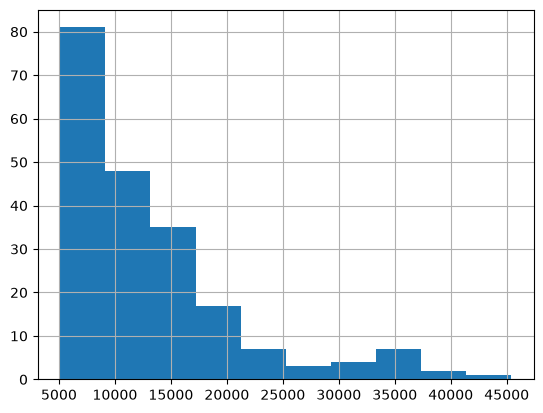

In [8]:
# Analyze the price column

Automobile['price'].hist()

<Axes: >

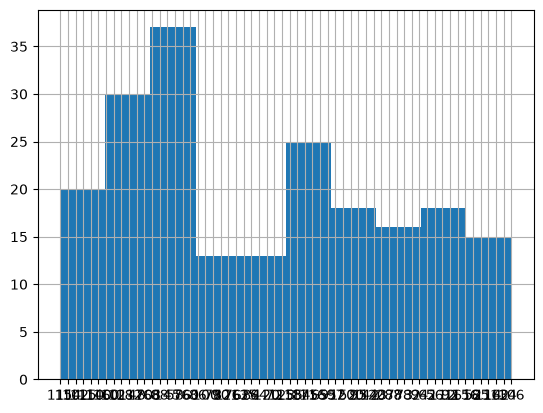

In [9]:
## Analyze the horsepower column

Automobile['horsepower'].hist()

<Axes: >

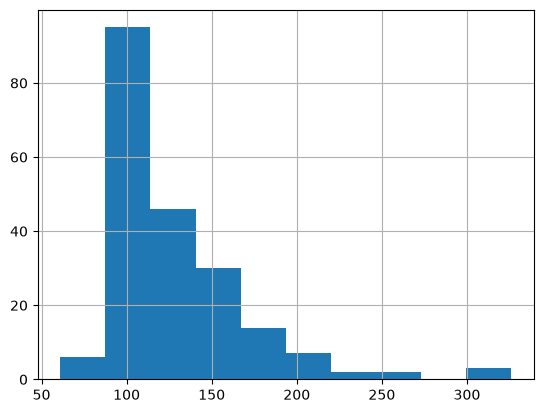

In [10]:
## Analyze the engine-size column

Automobile['engine-size'].hist()

<Axes: >

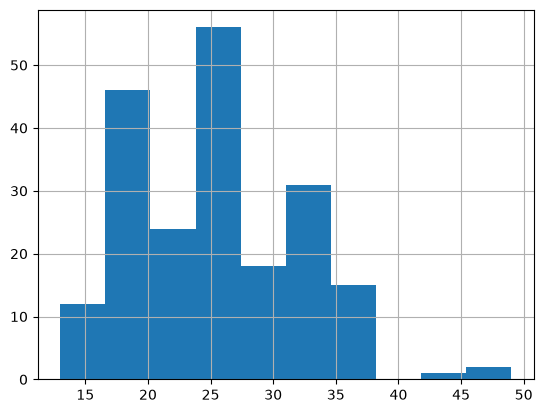

In [11]:
## Analyze the city-mpg column

Automobile['city-mpg'].hist()

## Task 4: Improve Data Quality



In [12]:
## Standardize the dataset

Automobile.replace("?", np.nan, inplace = True)


,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,NaN,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,NaN,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,sedan,rwd,front,68.9,55.5,ohc,141,114,23,28,16845
201,-1,95,volvo,gas,sedan,rwd,front,68.8,55.5,ohc,141,160,19,25,19045
202,-1,95,volvo,gas,sedan,rwd,front,68.9,55.5,ohcv,173,134,18,23,21485
203,-1,95,volvo,diesel,sedan,rwd,front,68.9,55.5,ohc,145,106,26,27,22470


In [13]:
## Convert Columns to Numeric

Automobile["normalized-losses"] = pd.to_numeric(Automobile["normalized-losses"], errors='coerce')

Automobile["horsepower"]= pd.to_numeric(Automobile["horsepower"], errors='coerce')

In [15]:
## Handle Missing Values

Automobile.isnull().sum()

symboling             0
normalized-losses    41
make                  0
fuel-type             0
body-style            0
drive-wheels          0
engine-location       0
width                 0
height                0
engine-type           0
engine-size           0
horsepower            2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

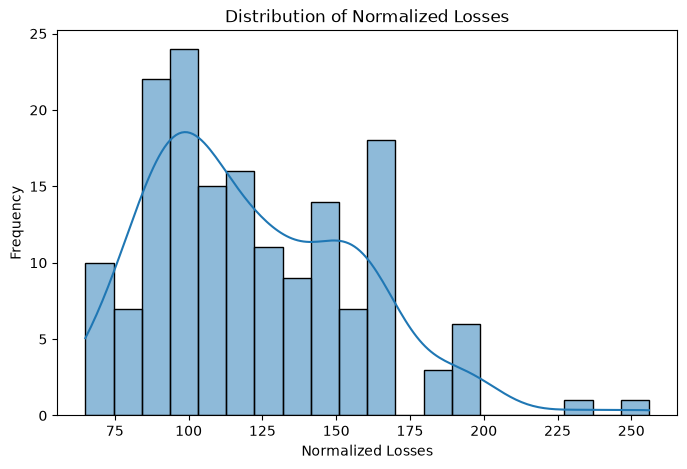

skewness of normalized-losses column: 0.7659764175950632 3


In [19]:
## Plot histogram to understand the skewness of these columns

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure( figsize=(8,5))

sns.histplot(Automobile['normalized-losses'], kde=True, bins=20)


plt.title("Distribution of Normalized Losses")
plt.xlabel("Normalized Losses")
plt.ylabel("Frequency")

plt.show()

print("skewness of normalized-losses column:", Automobile['normalized-losses'].skew(),3)

In [20]:
## According to the skewness value, fill the missing values with the required central tendency

Automobile['normalized-losses'].fillna(Automobile['normalized-losses'].median(), inplace=True)

C:\Users\PRITESH AMBRE\AppData\Local\Temp\ipykernel_15024\3106023570.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  Automobile['normalized-losses'].fillna(Automobile['normalized-losses'].median(), inplace=True)


0      115.0
1      115.0
2      115.0
3      164.0
4      164.0
       ...  
200     95.0
201     95.0
202     95.0
203     95.0
204     95.0
Name: normalized-losses, Length: 205, dtype: float64

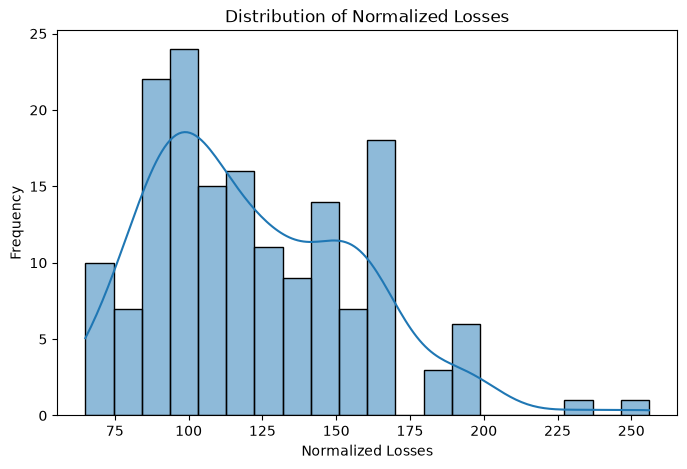

Skewness of Normalized Losses: 0.766


In [26]:
## Now plot the histogram for another column with missing Values

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    data=Automobile,
    x='normalized-losses',
    bins=20,
    kde=True
)

plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')

plt.show()

# Skewness Value
print("Skewness of Normalized Losses:",
      round(Automobile['normalized-losses'].skew(), 3))






In [28]:
## According to the skewness value, fill the missing values with the required central tendency

Automobile['normalized-losses'].fillna(
    Automobile['normalized-losses'].median(),
    inplace=True
)

C:\Users\PRITESH AMBRE\AppData\Local\Temp\ipykernel_15024\3944658474.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  Automobile['normalized-losses'].fillna(


0      115.0
1      115.0
2      115.0
3      164.0
4      164.0
       ...  
200     95.0
201     95.0
202     95.0
203     95.0
204     95.0
Name: normalized-losses, Length: 205, dtype: float64

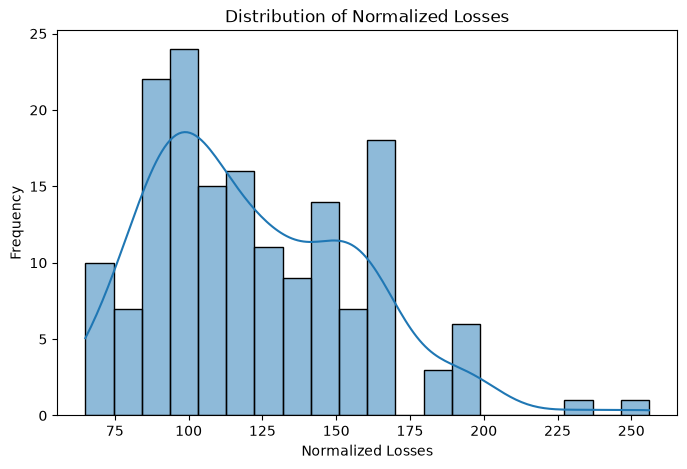

Skewness of Normalized Losses: 0.766


In [29]:
## Now plot the histogram for another column with missing Values

plt.figure(figsize=(8,5))

sns.histplot(
    data=Automobile,
    x='normalized-losses',
    bins=20,
    kde=True
)

plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')

plt.show()

# Skewness Value
print("Skewness of Normalized Losses:",
      round(Automobile['normalized-losses'].skew(), 3))

In [30]:
## Fill the missing value with Central tendency

Automobile['horsepower'].fillna(
    Automobile['horsepower'].median(),
    inplace=True
)

C:\Users\PRITESH AMBRE\AppData\Local\Temp\ipykernel_15024\2562998394.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  Automobile['horsepower'].fillna(


0      111.0
1      111.0
2      154.0
3      102.0
4      115.0
       ...  
200    114.0
201    160.0
202    134.0
203    106.0
204    114.0
Name: horsepower, Length: 205, dtype: float64

In [32]:
## Check that no values are missing

Automobile.isnull().sum()

symboling             0
normalized-losses    41
make                  0
fuel-type             0
body-style            0
drive-wheels          0
engine-location       0
width                 0
height                0
engine-type           0
engine-size           0
horsepower            2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [33]:
## Check Duplicate Records

Automobile.duplicated().sum()

np.int64(0)

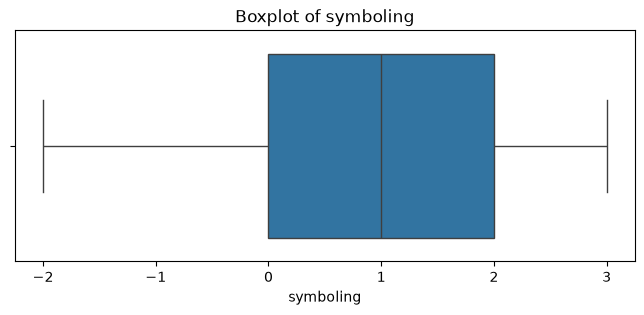

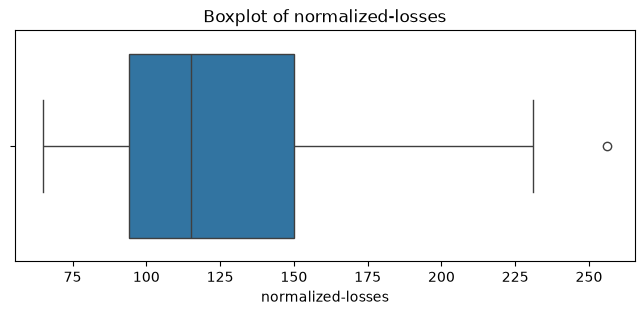

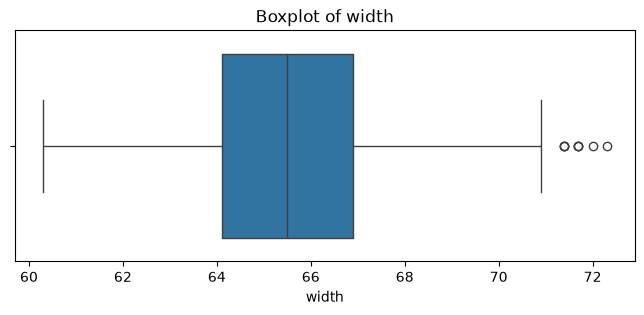

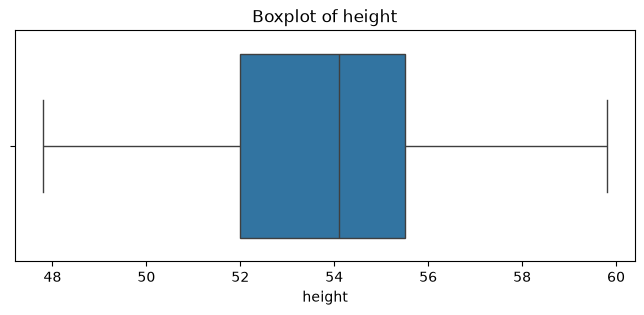

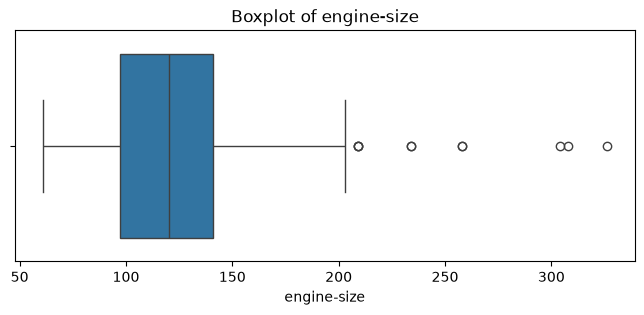

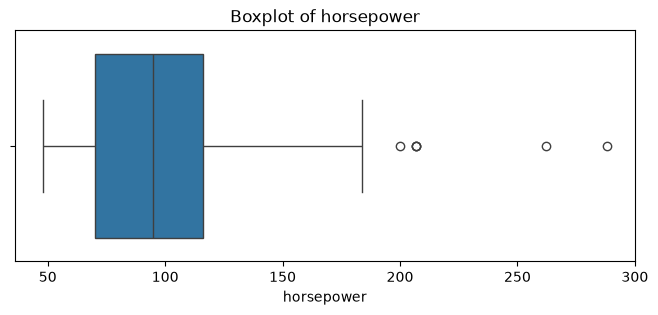

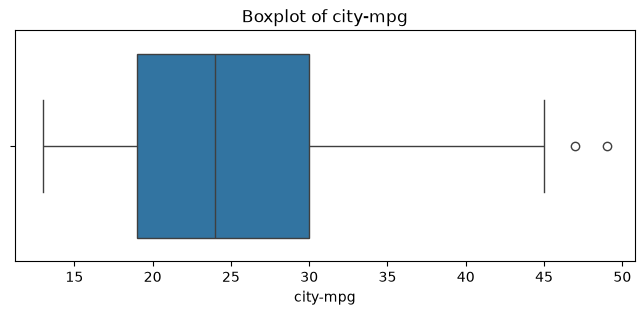

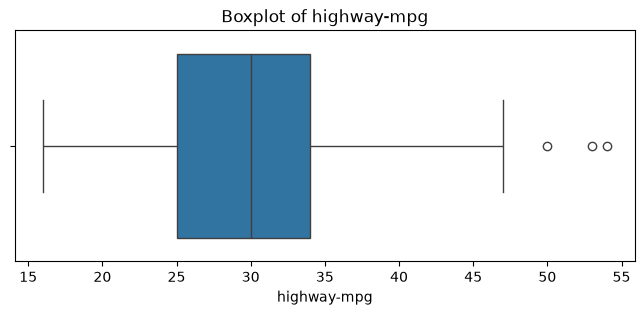

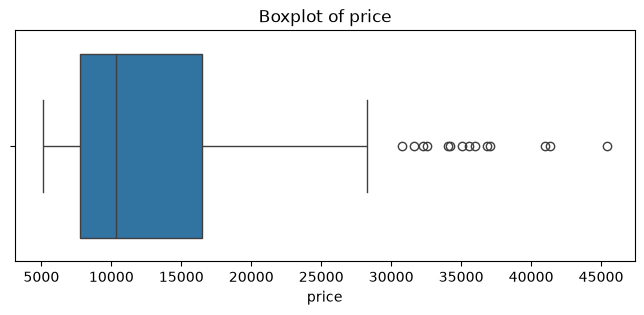

In [35]:
## Handle the Outliers

num_cols = Automobile.select_dtypes(include=np.number).columns

for col in num_cols:
    
    plt.figure(figsize=(8, 3))
    
    sns.boxplot(x=Automobile[col])
    
    plt.title(f'Boxplot of {col}')
    
    plt.show()

In [36]:
## Observe the Boxplots and handle the outliers using IQR or  z score based on whether it is normally distributed or not

num_cols = Automobile.select_dtypes(include=np.number).columns

for col in num_cols:

    Q1 = Automobile[col].quantile(0.25)
    Q3 = Automobile[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    Automobile = Automobile[
        (Automobile[col] >= lower_bound) &
        (Automobile[col] <= upper_bound)
    ]

print("Shape after outlier removal:", Automobile.shape)

Shape after outlier removal: (127, 15)


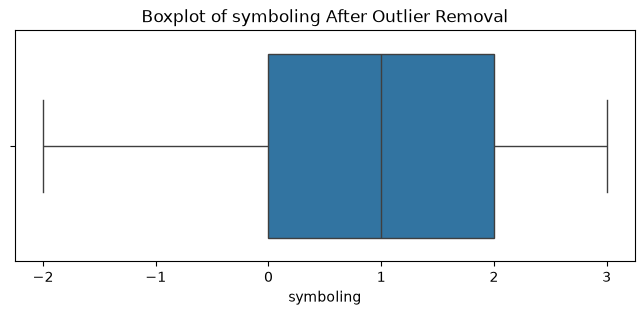

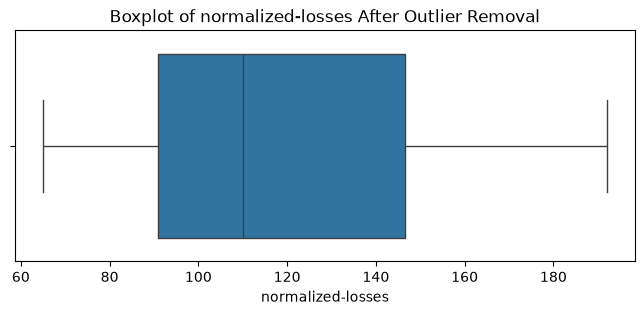

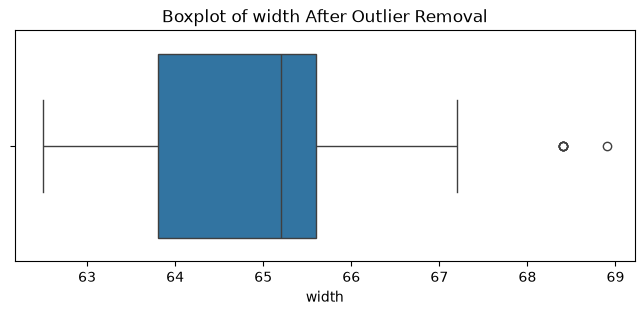

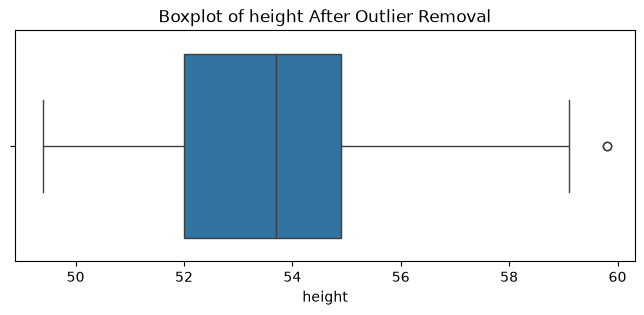

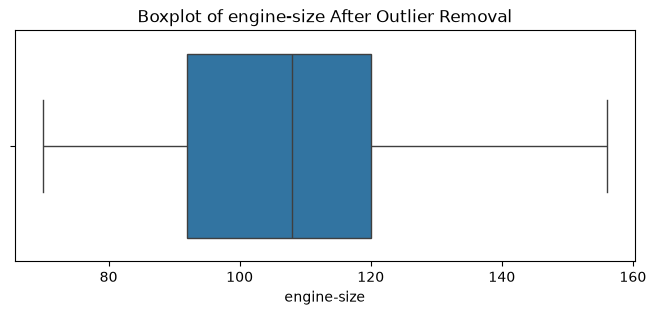

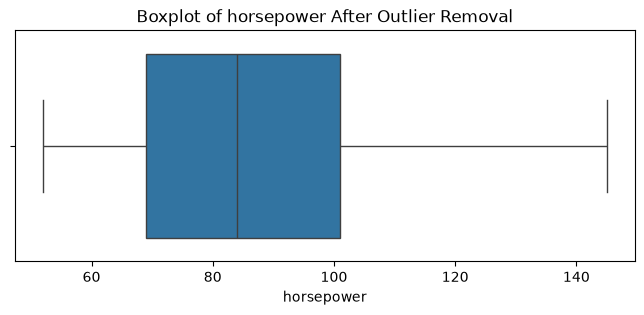

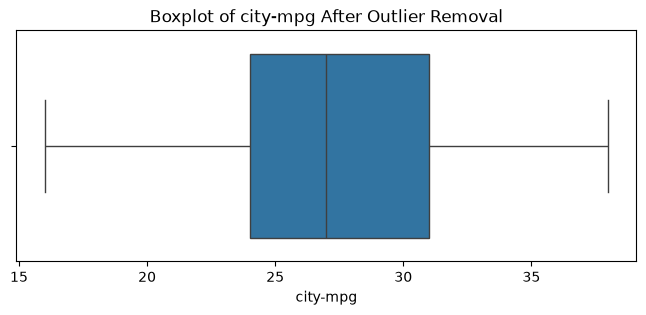

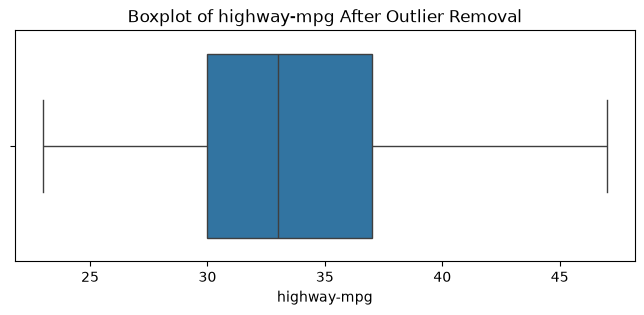

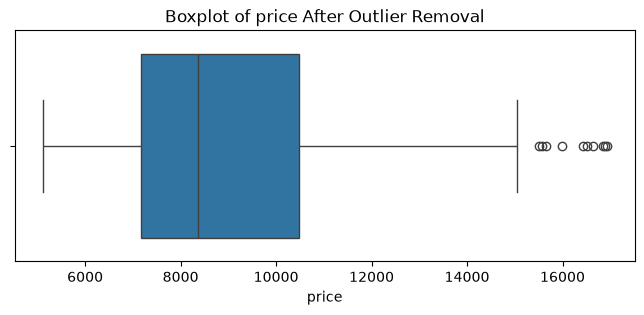

In [37]:
## Verify that there are no outliers left

for col in num_cols:

    plt.figure(figsize=(8,3))

    sns.boxplot(x=Automobile[col])

    plt.title(f'Boxplot of {col} After Outlier Removal')

    plt.show()

## Task 4: Encode Categorical Data



In [38]:
## Identify the Categorical Columns and Numerical Columns

Automobile_num=Automobile.select_dtypes(["int64","float64"])
Automobile_cat=Automobile.select_dtypes(object)

C:\Users\PRITESH AMBRE\AppData\Local\Temp\ipykernel_15024\1900706350.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Automobile_cat=Automobile.select_dtypes(object)


In [39]:
##Select type of encoding for Categorical Columns

Automobile_cat.info()

<class 'pandas.DataFrame'>
Index: 127 entries, 3 to 200
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   make             127 non-null    str  
 1   fuel-type        127 non-null    str  
 2   body-style       127 non-null    str  
 3   drive-wheels     127 non-null    str  
 4   engine-location  127 non-null    str  
 5   engine-type      127 non-null    str  
dtypes: str(6)
memory usage: 6.9 KB


In [43]:
from sklearn.preprocessing import LabelEncoder
for col in Automobile_cat :
    le=LabelEncoder() #create the object of LabelEncoder class
    Automobile_cat[col]=le.fit_transform(Automobile_cat[col])

In [44]:

Automobile_cat.head()

,make,fuel-type,body-style,drive-wheels,engine-location,engine-type
3,0,1,2,1,0,2
10,1,1,2,2,0,2
11,1,1,2,2,0,2
19,2,1,1,1,0,2
20,2,1,2,1,0,2
